In [2]:
## Part 1: Load the data

In [3]:
import pandas as pd
import re

df = pd.read_csv(r"C:\Users\tim\Documents\ANN project\Combined .csv")
print("Raw rows:", len(df))
df.head()

Raw rows: 10106


,Sr. No.,News Items,Label
0,1,ٹی ٹی پی نے پنجاب حکومت کے ہیلی کاپٹر کے عملے ...,FAKE
1,2,مارک زکربرگ سیاست میں آنے کا سوچ رہے ہیں۔,FAKE
2,3,فریدہ جلال نے اپنی موت کی افواہوں پر تنقید کی۔,FAKE
3,4,جعلی خبریں: پاپ اسٹار حدیقہ کیانی نے جعلی منشی...,FAKE
4,5,صنم ماروی نے میڈیا پر گردش کرنے والی زیادتی او...,FAKE


In [4]:
## Part 2: Check data quality

In [5]:
print("Empty rows:")
print(df.isna().sum())

print("\nAll label values (note the spaces):")
print(df['Label'].value_counts().to_dict())

print("\nDuplicate news items:", df.duplicated(subset='News Items').sum())

print("\nThe stray header row in the middle:")
print(df[df['Label'] == 'Label'])

Empty rows:
Sr. No.       22
News Items    22
Label         22
dtype: int64

All label values (note the spaces):
{'FAKE': 5039, 'TRUE': 4997, 'TRUE ': 33, 'FAKE ': 14, 'Label': 1}

Duplicate news items: 869

The stray header row in the middle:
      Sr. No.  News Items  Label
5053  Sr. No.  News Items  Label


In [6]:
# Part 3: Fix the rows

In [7]:
df = df.dropna(subset=['News Items', 'Label'])
print("After removing empty rows:", len(df))

df['Label'] = df['Label'].str.strip()
df = df[df['Label'].isin(['TRUE', 'FAKE'])]
print("After fixing labels:", len(df))

df = df.drop_duplicates(subset='News Items')
print("After removing duplicates:", len(df))

print("\nLabels now:", df['Label'].value_counts().to_dict())

After removing empty rows: 10084
After fixing labels: 10083
After removing duplicates: 9235

Labels now: {'FAKE': 4637, 'TRUE': 4598}


In [8]:
## Part 4: Clean the Urdu text

In [9]:
def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)                          # 1 links
    text = re.sub(r'^\s*[^\s(]{1,20}\s*\([^)]{1,25}\)', ' ', text)         # 2 source tag
    text = (text.replace('ي', 'ی').replace('ى', 'ی')
                .replace('ك', 'ک').replace('ه', 'ہ'))                      # 3 Arabic → Urdu
    text = re.sub(r'[\u064B-\u0652\u0670]', '', text)                      # 4 zer/zabar/pesh
    text = text.lower()                                                    # 5 English lowercase
    text = re.sub(r'[0-9\u06F0-\u06F9\u0660-\u0669]', ' ', text)           # 6 digits
    text = re.sub(r'[^\u0600-\u06FFa-z\s]', ' ', text)                     # 7 keep letters only
    text = re.sub(r'[\u06D4\u060C\u061F\u061B]', ' ', text)                # 8 Urdu punctuation
    text = re.sub(r'\s+', ' ', text).strip()                               # 9 extra spaces
    return text

# Test on a made-up messy message
test = "کراچی (ویب ڈیسک) CPEC پر 25 اہم خبريں! www.fake.com کِتاب۔"
print("BEFORE:", test)
print("AFTER: ", clean_text(test))

# Clean every news item
df['clean'] = df['News Items'].apply(clean_text)

print("\nReal example:")
print("BEFORE:", df['News Items'].iloc[5])
print("AFTER: ", df['clean'].iloc[5])

BEFORE: کراچی (ویب ڈیسک) CPEC پر 25 اہم خبريں! www.fake.com کِتاب۔
AFTER:  cpec پر اہم خبریں کتاب

Real example:
BEFORE: نواز شریف نے واقعی کرپشن کی وجہ سے ڈیووس میں تقریر کرنے سے منع کیا۔
AFTER:  نواز شریف نے واقعی کرپشن کی وجہ سے ڈیووس میں تقریر کرنے سے منع کیا


In [10]:
## Part 5: Labels, length check and save

Final rows: 9235
{'FAKE': 4637, 'TRUE': 4598}

Average words per item:
Label
FAKE    116.3
TRUE     33.0
Name: words, dtype: float64


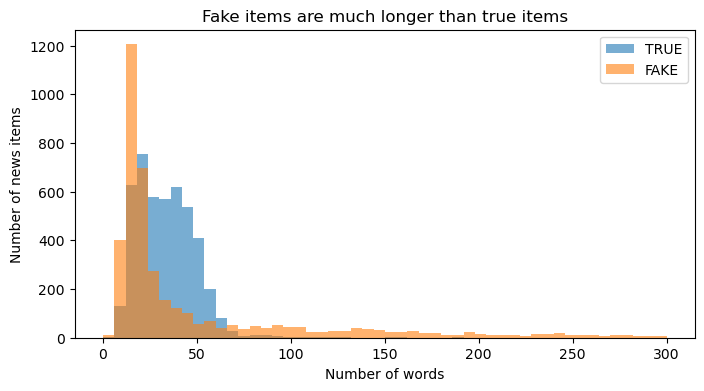

Saved cleaned_data.csv


In [11]:
import matplotlib.pyplot as plt

# 1. Count words in each cleaned text, drop near-empty ones
df['words'] = df['clean'].str.split().str.len()
df = df[df['words'] >= 3]

# 2. Turn labels into numbers
df['label'] = (df['Label'] == 'FAKE').astype(int)

print("Final rows:", len(df))
print(df['Label'].value_counts().to_dict())

# 3. The length trap
print("\nAverage words per item:")
print(df.groupby('Label')['words'].mean().round(1))

plt.figure(figsize=(8, 4))
plt.hist(df[df['label'] == 0]['words'], bins=50, range=(0, 300), alpha=0.6, label='TRUE')
plt.hist(df[df['label'] == 1]['words'], bins=50, range=(0, 300), alpha=0.6, label='FAKE')
plt.xlabel('Number of words')
plt.ylabel('Number of news items')
plt.title('Fake items are much longer than true items')
plt.legend()
plt.show()

# 4. Save the clean data
df[['clean', 'label', 'words']].to_csv('cleaned_data.csv', index=False, encoding='utf-8-sig')
print("Saved cleaned_data.csv")

In [12]:
# Part 6: Prepare data for training

In [13]:
from sklearn.model_selection import train_test_split

data = pd.read_csv('cleaned_data.csv')

# Cut every text to its first 40 words
MAX_WORDS = 40
data['text'] = data['clean'].str.split().str[:MAX_WORDS].str.join(' ')

# Split: 70% train, 15% validation, 15% test
train, temp = train_test_split(data, test_size=0.30, stratify=data['label'], random_state=42)
val, test   = train_test_split(temp, test_size=0.50, stratify=temp['label'], random_state=42)

print("Train:", len(train), " Validation:", len(val), " Test:", len(test))
print("Fake share in each:",
      round(train['label'].mean(), 3), round(val['label'].mean(), 3), round(test['label'].mean(), 3))

Train: 6464  Validation: 1385  Test: 1386
Fake share in each: 0.502 0.502 0.502


In [14]:
## Part 7: TF-IDF and baselines

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# 1. Turn text into numbers
tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(train['text'])
X_val   = tfidf.transform(val['text'])
X_test  = tfidf.transform(test['text'])
y_train, y_val, y_test = train['label'], val['label'], test['label']
print("Train matrix shape:", X_train.shape)

# 2. Baseline A: length only (can word count alone guess the label?)
len_model = LogisticRegression().fit(train[['words']], y_train)
print("Length-only accuracy (validation):", round(accuracy_score(y_val, len_model.predict(val[['words']])), 3))

# 3. Baseline B: logistic regression on TF-IDF
lr_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
print("Logistic regression accuracy (validation):", round(accuracy_score(y_val, lr_model.predict(X_val)), 3))

# 4. Which words push towards FAKE or TRUE?
words = np.array(tfidf.get_feature_names_out())
weights = lr_model.coef_[0]
print("\nTop FAKE words:", words[np.argsort(weights)[-10:]][::-1])
print("Top TRUE words:", words[np.argsort(weights)[:10]])

Train matrix shape: (6464, 5000)
Length-only accuracy (validation): 0.617
Logistic regression accuracy (validation): 0.824

Top FAKE words: ['لئے' 'ویڈیو' 'ٹرمپ' 'تصویر' 'وائرل' 'نہیں' 'جعلی' 'دعوی' 'کرونا' 'شام']
Top TRUE words: ['لیے' 'کہا' 'ہندوستان' 'ٹیسٹ' 'جموں' 'مرکز' 'اور' 'حکام' 'زیادہ' 'بہار']


In [16]:
import tensorflow as tf
print(tf.__version__)

2.18.1


In [17]:
## Part 8: Feed-forward neural network

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,449 (2.47 MB)

 Trainable params: 648,449 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7084 - loss: 0.5732 - val_accuracy: 0.8318 - val_loss: 0.3860
Epoch 2/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8786 - loss: 0.3008 - val_accuracy: 0.8440 - val_loss: 0.3640
Epoch 3/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9335 - loss: 0.1833 - val_accuracy: 0.8383 - val_loss: 0.4156
Epoch 4/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9623 - loss: 0.1120 - val_accuracy: 0.8303 - val_loss: 0.4878
Epoch 5/30
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9765 - loss: 0.0694 - val_accuracy: 0.8310 - val_loss: 0.5284


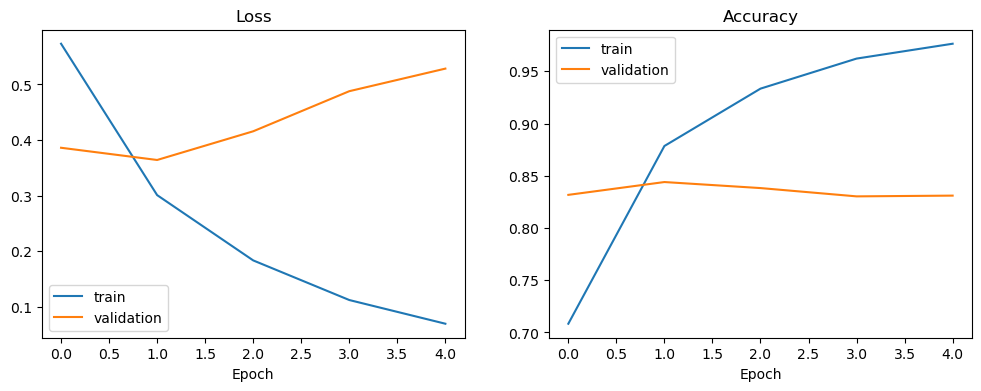

Neural network accuracy (validation): 0.844


In [18]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

# 1. Keras needs normal (dense) arrays, not sparse ones
Xtr = X_train.toarray().astype('float32')
Xva = X_val.toarray().astype('float32')
Xte = X_test.toarray().astype('float32')

# 2. Build the network
model = Sequential([
    Input(shape=(5000,)),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# 3. Tell it how to learn
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

# 4. Train, stopping when validation stops improving
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(Xtr, y_train,
                    validation_data=(Xva, y_val),
                    epochs=30, batch_size=32,
                    callbacks=[early_stop], verbose=1)

# 5. Plot learning curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

val_loss, val_acc = model.evaluate(Xva, y_val, verbose=0)
print("Neural network accuracy (validation):", round(val_acc, 3))

In [19]:
## Part 9: Test set evaluation

              Model  Accuracy  Precision  Recall    F1
        Length only     0.615      0.750   0.349 0.476
Logistic regression     0.848      0.865   0.828 0.846
     Neural network     0.859      0.856   0.865 0.861

Neural network, per class:
              precision    recall  f1-score   support

        TRUE       0.86      0.85      0.86       690
        FAKE       0.86      0.86      0.86       696

    accuracy                           0.86      1386
   macro avg       0.86      0.86      0.86      1386
weighted avg       0.86      0.86      0.86      1386



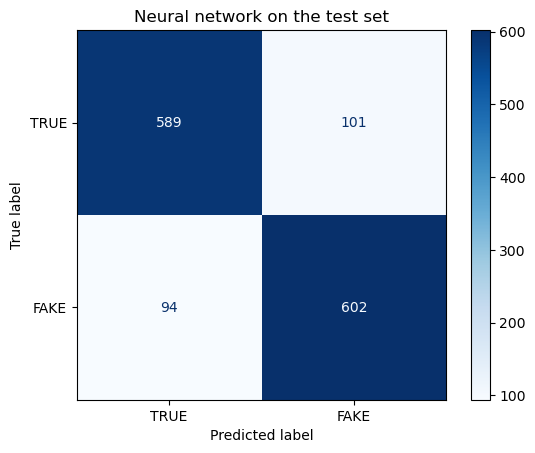

In [20]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# 1. Predictions from all three models on the test set
nn_prob = model.predict(Xte, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
lr_pred = lr_model.predict(X_test)
len_pred = len_model.predict(test[['words']])

# 2. One comparison table
results = []
for name, pred in [('Length only', len_pred),
                   ('Logistic regression', lr_pred),
                   ('Neural network', nn_pred)]:
    results.append({'Model': name,
                    'Accuracy':  round(accuracy_score(y_test, pred), 3),
                    'Precision': round(precision_score(y_test, pred), 3),
                    'Recall':    round(recall_score(y_test, pred), 3),
                    'F1':        round(f1_score(y_test, pred), 3)})
print(pd.DataFrame(results).to_string(index=False))

# 3. Detailed report for the neural network
print("\nNeural network, per class:")
print(classification_report(y_test, nn_pred, target_names=['TRUE', 'FAKE']))

# 4. Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, nn_pred, display_labels=['TRUE', 'FAKE'], cmap='Blues')
plt.title('Neural network on the test set')
plt.show()

In [21]:
import joblib

# 1. Save the trained network and the TF-IDF vocabulary
model.save('sach_check_model.keras')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
print("Saved: sach_check_model.keras and tfidf_vectorizer.pkl")

# 2. One function that does the full pipeline for any new message
def check_news(message):
    cleaned = clean_text(message)                            # same cleaning as training
    cleaned = ' '.join(cleaned.split()[:MAX_WORDS])          # same 40-word cut
    vector = tfidf.transform([cleaned]).toarray().astype('float32')  # same TF-IDF
    fake_score = float(model.predict(vector, verbose=0)[0][0])
    return fake_score

# 3. Try it
samples = [
    "وائرل ویڈیو میں دعوی کیا جا رہا ہے کہ حکومت نے تمام موبائل فون بند کرنے کا فیصلہ کر لیا ہے",
    "وزیراعظم نے کابینہ کے اجلاس میں بجٹ تجاویز کی منظوری دے دی",
    "سوشل میڈیا پر جعلی خبر پھیلائی جا رہی ہے کہ کل سے تمام سکول بند ہوں گے",
]
for s in samples:
    score = check_news(s)
    print(f"{score:.2f}  ->  {s}")

Saved: sach_check_model.keras and tfidf_vectorizer.pkl
0.99  ->  وائرل ویڈیو میں دعوی کیا جا رہا ہے کہ حکومت نے تمام موبائل فون بند کرنے کا فیصلہ کر لیا ہے
0.19  ->  وزیراعظم نے کابینہ کے اجلاس میں بجٹ تجاویز کی منظوری دے دی
0.97  ->  سوشل میڈیا پر جعلی خبر پھیلائی جا رہی ہے کہ کل سے تمام سکول بند ہوں گے
